# The Knight's Maze

### Lab 2 · Efficient Search

A knight (K) is tasked to retrieve the treasure (G) hidden in the dungeon without being caught by a dragon (D). 

In the second notebook, the Knight has only limited cognitive capabilities, represented by his '*thinking_budget*'. In the first lab you had just to find a way to solve the maze. In the second, you are also tasked in solving it without going over the allocated thinking budget. 

To pass the exercise, you can use the A\* algorithm that you saw in class, or try other methods to further improve efficiency. 

You can work on this page, on Google Colab, or locally (see *Running the code*). In any case, upload a notebook back on the platform once you are finished. 



<div style="text-align: center;">
    <img src="https://upload.wikimedia.org/wikipedia/commons/8/85/Weighted_A_star_with_eps_5.gif?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail_unscaled" width="500"/>
</div>

### AI Policy: 

While AI can be used, I do not recommended using it for directly writing the code to solve the exercises. [Preliminary research](https://arxiv.org/abs/2506.08872) shows reduced EEG connectivity when offloading to AI, inducing poorer retention. 

I recommend to try solving the exercise without AI, and interrogate AI on how to understand specific portions of the code, or how to use specific functions in python, rather than actually writing the code. 

The goal always not to solve the exercise, but to learn. When you will start working, you will probably be using mostly AI for writing code, - but if you can't understand the code that AI is writing, it will be impossible to debug or to understand the implication of what you are doing. 

***We ask you to disclose at the start of the notebook the kind of AI assistance that was used to solve the exercises.***

## The exercise

The dungeon is a grid of cells. In the initial version, the knight starts top-left, the treasure is bottom-right and the dragon starts in the middle. The base version is a 10*10 connected graph, with no walls. Additional versions have walls, like in this example: 

    █████████████████
    █ K .   █   .   █
    █   ·   █   ·   █
    █   .   █ D .   █
    █   █████   ·   █
    █   .   .   . G █
    █████████████████

**Rules.** Each turn the knight moves first, then the dragon. A move is a step (in the four directions, no diagonal moves) to a neighbouring cell with no wall in between, or staying still. The knight wins when it reaches the treasure. It loses if it ends up on the same cell as the dragon, or if 200 turns pass without reaching the treasure. 

<span style="color:teal">**New Rules.**</span>. For the new levels, there will be also an allocated *thinking_budget*. The thinking_budget refers to the amount of times *neighbours* is called inside the knight class. 


### The Notebook.

The notebook has a lot of code to draw the maze and to evaluate the runs. You don't have to read them and can simply run those. 

You should first familiarise with the maze, and be able to make the knight navigate it statically, by computing both BFS and Dijkstra on the static maze. 

Once you are able to draw paths across the maze, you can add those strategies to the knight. 


**Levels.** Levels 1 and 2 are required to pass. The others are optional and open-ended.

| Level | Dragon | Algorithm | To pass |
|---|---|---|---|
| 1 | `StaticDragon`: sleeps where it stands | BFS, with the dragon's cell treated as a wall | ≥ 95 % of 50 random mazes |
| 2 | `GuardDragon`: sleeps, but hunts you if you come within 3 steps of its lair | Dijkstra, with a cost that grows near the dragon | ≥ 75 % of 50 random mazes |
| 2.5 | `GreedyDragon` | your choice | 90 |
| 3 | `ChaserDragon` at half or full speed, on mazes with loops (`"density": 0.5`) | your choice | 70 |
| 4 | `StaticDragon` in a 20×20 dungeon (`density: 0.5`), treasure on the right edge, **thinking budget 280** | A\* with an admissible heuristic: BFS needs more than 300 lookups here | ≥ 95 % of 50 mazes |
| 5 | `StaticDragon` in an open 20×20 hall (`density: 0.3`), **thinking budget 120** | A\* alone is not enough: break ties well, or use a stronger heuristic | ≥ 95 % of 50 mazes |
| 6 | `PatrolDragon`: walks between its lair and the treasure, never standing on it; its rounds are in `state.dragon_at(k)`, **thinking budget 280** | A\* every turn with the dragon as a wall; or plan in time with the dragon's rounds | ≥ 90 % of 50 mazes |


**Testing** The last cell allows you to both have a visual experience of the maze, or to run evaluate on 50 mazes.


### From the lecture's uniform-cost search to A*

In the lecture you saw *Ricerca-grafo UC* (Russell & Norvig, *AIMA*, Fig. 3.14): a graph search whose
frontier is a priority queue ordered by the cost of the path so far, $f(n) = g(n)$.
**A\* is the same algorithm with one line changed**: the queue is ordered by

$$f(n) = g(n) + h(n)$$

where $g(n)$ is the cost of the path from the start to $n$ and $h(n)$ is a *heuristic*, an estimate of the
cost still to go. With $h = 0$ you get uniform-cost search back, which on a maze with unit step costs is
Dijkstra. Here is the lecture's pseudocode with that one line marked:

```text
function A*-SEARCH(problem, h) returns a solution, or failure
    node     ← a node with STATE = problem.INITIAL-STATE, PATH-COST = 0
    frontier ← a priority queue ordered by PATH-COST + h(STATE),   ◄ UC search orders by PATH-COST alone
               with node as the only element
    explored ← an empty set
    loop do
        if EMPTY?(frontier) then return failure
        node ← POP(frontier)                        /* the node with the lowest f */
        if problem.GOAL-TEST(node.STATE) then return SOLUTION(node)
        add node.STATE to explored
        for each action in problem.ACTIONS(node.STATE) do
            child ← CHILD-NODE(problem, node, action)
            if child.STATE is not in explored or frontier then
                frontier ← INSERT(child, frontier)
            else if child.STATE is in frontier with higher PATH-COST then
                replace that frontier node with child
```



In [80]:
"""The maze: a rows x cols grid graph, drawn as text.

Each cell (row, col) is a node, and two neighbouring cells are connected
unless there is a wall between them. A new maze has no walls. You can add
them through the `walls` parameter, with add_wall(), or with random_walls().

    maze = Maze(4, 6, walls=[((0, 0), (0, 1)), ((1, 2), (2, 2))])
    print(maze)

Walls are drawn as solid blocks, and cells are separated by faint dots so
the grid stays visible even with no walls. Paths are drawn as arrows
pointing to the next cell: single arrows for the knight, double arrows
for the dragon, and a cross where both passed.

Notebooks show a maze at the end of a cell as a picture instead, and
maze.draw() makes a picture with marks and paths (see the next cell).

Inside a `with maze.thinking(budget)` block the maze also counts the cells
whose neighbours you ask for: that is the knight's thinking budget. See
Maze.thinking() and the search cell below.
"""
import random
from contextlib import contextmanager

DIRECTIONS = ((-1, 0), (1, 0), (0, -1), (0, 1))  # up, down, left, right

WALL, DOT, BOTH = "█", "·", "✕"
ARROWS = {
    "knight": {(-1, 0): "↑", (1, 0): "↓", (0, -1): "←", (0, 1): "→"},
    "dragon": {(-1, 0): "⇑", (1, 0): "⇓", (0, -1): "⇐", (0, 1): "⇒"},
}


def manhattan(a, b):
    """Grid distance between two cells, ignoring walls."""
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def path_arrows(path, arrows):
    """{cell: arrow pointing to the next cell on the path}. A cell visited
    more than once keeps its latest arrow; the last cell gets none."""
    out = {}
    for a, b in zip(path, path[1:]):
        if a != b:
            out[tuple(a)] = arrows[(b[0] - a[0], b[1] - a[1])]
    return out


class OutOfThought(Exception):
    """A search looked at more cells than its thinking budget allows."""


class Maze:
    def __init__(self, rows=10, cols=None, walls=()):
        """A rows x cols maze (square if cols is omitted).

        `walls` is a list of pairs of neighbouring cells with a wall between
        them, e.g. [((0, 0), (0, 1))] puts a wall between the two top-left
        cells.
        """
        self.rows = rows
        self.cols = rows if cols is None else cols
        self.walls = set()
        for a, b in walls:
            self.add_wall(a, b)
        self.looked, self._budget, self._counting = [], None, False   # see thinking()

    # ---------- cells and walls ----------

    def in_bounds(self, cell):
        r, c = cell
        return 0 <= r < self.rows and 0 <= c < self.cols

    def cells(self):
        """All cells, row by row."""
        return [(r, c) for r in range(self.rows) for c in range(self.cols)]

    def _edge(self, a, b):
        a, b = tuple(a), tuple(b)
        if not (self.in_bounds(a) and self.in_bounds(b)) or manhattan(a, b) != 1:
            raise ValueError(
                f"a wall must separate two neighbouring cells inside the "
                f"{self.rows}x{self.cols} maze, got {a} and {b}")
        return frozenset((a, b))

    def add_wall(self, a, b):
        self.walls.add(self._edge(a, b))

    def _open(self, a, b):
        """True if you can step directly from cell a to cell b. Free: used by
        the drawing code and by neighbours()."""
        return (self.in_bounds(a) and self.in_bounds(b) and manhattan(a, b) == 1
                and frozenset((a, b)) not in self.walls)

    def is_open(self, a, b):
        """True if you can step directly from cell a to cell b. Costs one unit
        of thinking, see thinking()."""
        self._charge(a)
        return self._open(a, b)

    # ---------- graph view ----------

    def neighbours(self, cell):
        """Cells you can step to from `cell` (up, down, left, right). Costs
        one unit of thinking, see thinking()."""
        self._charge(cell)
        r, c = cell
        return [(r + dr, c + dc) for dr, dc in DIRECTIONS
                if self._open(cell, (r + dr, c + dc))]

    __getitem__ = neighbours        # maze[cell] is the same as maze.neighbours(cell)

    def adjacency(self):
        """The whole maze as an adjacency list: {cell: [neighbours]}."""
        return {cell: self.neighbours(cell) for cell in self.cells()}

    # ---------- thinking ----------

    @contextmanager
    def thinking(self, budget=None):
        """Count the cells looked at inside the block, and stop at `budget`.

            with maze.thinking(budget=50):
                path = bfs(maze, start, goal)
            maze.expanded      how many cells the search looked at
            maze.looked        those cells, in order (to draw them)

        One unit of thinking = one request for the neighbours of a cell:
        maze.neighbours(cell), maze[cell], state.moves_from(cell) and
        maze.is_open(a, b) cost 1 each; maze.adjacency() costs one per cell;
        asking twice for the same cell costs twice. Everything else is free,
        and outside the block nothing is counted. When the budget runs out
        the next request raises OutOfThought. Blocks nest: one opened inside
        another keeps the outer count and budget, so a search that opens its
        own block cannot escape the budget it is run under.
        """
        if self._counting:
            yield self
            return
        self.looked, self._budget, self._counting = [], budget, True
        try:
            yield self
        finally:
            self._counting = False

    @property
    def expanded(self):
        """How many cells the last thinking() block looked at."""
        return len(self.looked)

    def _charge(self, cell):
        if self._counting:
            if self._budget is not None and len(self.looked) >= self._budget:
                raise OutOfThought(f"looked at {len(self.looked)} cells, the budget is "
                                   f"{self._budget}; could not look at {tuple(cell)}")
            self.looked.append(tuple(cell))

    # ---------- drawing ----------

    def _wall_above(self, r, c):
        """Wall on the top edge of cell (r, c); r == rows is the bottom border."""
        return r in (0, self.rows) or not self._open((r - 1, c), (r, c))

    def _wall_left(self, r, c):
        """Wall on the left edge of cell (r, c); c == cols is the right border."""
        return c in (0, self.cols) or not self._open((r, c - 1), (r, c))

    def _wall_at_corner(self, r, c):
        """True if any wall segment touches the corner point (r, c)."""
        return ((c < self.cols and self._wall_above(r, c))
                or (c > 0 and self._wall_above(r, c - 1))
                or (r < self.rows and self._wall_left(r, c))
                or (r > 0 and self._wall_left(r - 1, c)))

    def render(self, marks=None, knight_path=(), dragon_path=()):
        """The maze as text.

        `marks` maps cells to single characters, e.g. {(0, 0): "K"}, and is
        drawn on top of the paths; `knight_path` and `dragon_path` are
        lists of cells, drawn as arrows.
        """
        km = path_arrows(list(knight_path), ARROWS["knight"])
        dm = path_arrows(list(dragon_path), ARROWS["dragon"])
        symbols = {cell: BOTH if cell in km and cell in dm else km.get(cell) or dm[cell]
                   for cell in set(km) | set(dm)}
        symbols.update({tuple(cell): ch for cell, ch in (marks or {}).items()})

        lines = []
        for r in range(self.rows + 1):
            line = ""
            for c in range(self.cols + 1):
                line += WALL if self._wall_at_corner(r, c) else DOT
                if c < self.cols:
                    line += WALL * 3 if self._wall_above(r, c) else "   "
            lines.append(line)
            if r < self.rows:
                line = ""
                for c in range(self.cols + 1):
                    line += WALL if self._wall_left(r, c) else " "
                    if c < self.cols:
                        line += " " + symbols.get((r, c), " ") + " "
                lines.append(line)
        return "\n".join(lines)

    def __str__(self):
        return self.render()

    __repr__ = __str__  # shown where pictures can't be

    def draw(self, marks=None, knight_path=(), dragon_path=(), caption=""):
        """The drawing of render() as a picture: notebooks show it as an image
        (at the end of a cell, or with display()), print() as text."""
        text = self.render(marks, knight_path, dragon_path)
        return Drawing(maze_svg(self, marks, knight_path, dragon_path, caption),
                       text + "\n" + caption if caption else text)

    def _repr_svg_(self):
        """The picture notebooks show when a maze ends a cell."""
        return maze_svg(self)


def random_walls(rows, cols=None, density=0.8, seed=None):
    """Walls for a random maze in which every cell can be reached.

    It first builds a "perfect" maze, with exactly one path between any two
    cells, by randomised depth-first search, then keeps each of its walls
    with probability `density`. density=1 gives the perfect maze, which has
    no loops, so a dragon can always corner the knight in a dead end; lower
    values knock walls down and open up loops; density=0 gives no walls.
    """
    cols = rows if cols is None else cols
    rng = random.Random(seed)
    seen, stack, passages = {(0, 0)}, [(0, 0)], set()
    while stack:
        r, c = stack[-1]
        options = [(r + dr, c + dc) for dr, dc in DIRECTIONS
                   if 0 <= r + dr < rows and 0 <= c + dc < cols
                   and (r + dr, c + dc) not in seen]
        if options:
            nxt = rng.choice(options)
            seen.add(nxt)
            stack.append(nxt)
            passages.add(frozenset(((r, c), nxt)))
        else:
            stack.pop()

    walls = []
    for r in range(rows):
        for c in range(cols):
            for nb in ((r, c + 1), (r + 1, c)):
                if nb[0] < rows and nb[1] < cols:
                    if frozenset(((r, c), nb)) not in passages and rng.random() < density:
                        walls.append(((r, c), nb))
    return walls

In [81]:
"""Pictures of the maze: the board drawn as an SVG image, with sprites for
the knight, the dragon and the treasure.

In Jupyter, Colab and the course portal, a maze or a game at the end of a
cell is shown as a picture, and play() animates it; print() still gives
the text drawing. maze.draw() takes the same arguments as maze.render():

    maze.draw({(0, 0): "K", (9, 9): "G"}, knight_path=path)

The marks K, D and G are drawn as the knight, the dragon and the treasure,
and X as the knight caught by the dragon; any other mark as a character.
STYLE picks the look: "token", "pixel" or "line".
"""
from html import escape

STYLE = "token"
CELL, PAD, LINE_HEIGHT = 40, 12, 18   # pixels: a maze cell, the margin, a caption line
FONT = 'font-family="ui-monospace, Menlo, Consolas, monospace"'
CHAR_WIDTH = 7.2                      # pixels per caption character in that font


def _pixels(art, palette):
    """SVG rectangles for pixel art: one string per row, one character per
    pixel, "." for none. A run of one colour in a row is one rectangle."""
    rects = []
    for y, row in enumerate(art):
        x = 0
        while x < len(row):
            end = x
            while end < len(row) and row[end] == row[x]:
                end += 1
            if row[x] != ".":
                rects.append(f'<rect x="{x}" y="{y}" width="{end - x}" height="1" fill="{palette[row[x]]}"/>')
            x = end
    return "".join(rects)


def _mirror(halves):
    """Rows of symmetric pixel art, from their left halves."""
    return [half + half[::-1] for half in halves]


def _token(face, rim, emblem):
    """A round game token with an emblem, in a 100 x 100 box."""
    return ('<ellipse cx="50" cy="93" rx="32" ry="5" fill="#000" fill-opacity=".35"/>'
            f'<circle cx="50" cy="49" r="44" fill="{rim}"/><circle cx="50" cy="46" r="42" fill="{face}"/>'
            '<path d="M19 33a38 38 0 0 1 62 0" fill="none" stroke="#fff" stroke-opacity=".25" '
            'stroke-width="4" stroke-linecap="round"/>' + emblem)


def _line(ink, paper, body):
    """A line icon in a 100 x 100 box, filled with the paper colour so trails don't show through."""
    return (f'<g fill="{paper}" stroke="{ink}" stroke-width="5" stroke-linecap="round" '
            f'stroke-linejoin="round">{body}</g>')


KNIGHT_PIXELS = [
    "...........rr...",
    "..........rRr...",
    ".........rRr....",
    ".....ooorRo.....",
    "....oswssSSo....",
    "...osswsssSSo...",
    "...osswsssSSo...",
    "...osooooooSo...",
    "...osswsssSSo...",
    "...osossssoSo...",
    "...osswsssSSo...",
    "...osossssoSo...",
    "....osssssSo....",
    "..oooooooooooo..",
    ".obbbbbyybbbbBo.",
    ".obbbbbyybbbbBo.",
]
DRAGON_PIXELS = _mirror([
    "h.......",
    "hh......",
    ".hh.....",
    "..hh....",
    "...hoooo",
    "oo.ogggg",
    "ogoggggg",
    ".ogooggg",
    ".ogyykgg",
    "..oggggg",
    "...ogggg",
    "...oGggg",
    "....oggg",
    "....ogng",
    "....oggg",
    ".....ofo",
])
CHEST_PIXELS = [
    "............s...",
    "...........sss..",
    "............s...",
] + _mirror([
    "..oooooo",
    ".owywwww",
    "owwywwww",
    "owWyWWWW",
    "oyyyyyyy",
    "oWWyWWyy",
    "oWWyWWyk",
    "oWWyWWyy",
    "owwywwww",
    "owwywwww",
    "oWWyWWWW",
    "oooooooo",
    "........",
])

STYLES = {
    "token": {
        "background": "#1c1f26", "floor": "#2b303b", "tile": None, "dot": "#414858",
        "wall": "#cdbd9c", "wall_width": 6, "wall_cap": "round", "trail_dash": None,
        "knight": "#7fb0ff", "dragon": "#ff7a6b", "text": "#c9ced8", "won": "#7ddc8f", "lost": "#ff8a7a",
        "sprite": 36, "crisp": False,
        "sprites": {
            "K": ("0 0 100 100", _token("#3567d6", "#213f8a",
                '<path d="M50 23c0-9 9-15 22-13-7 3-11 8-12 15z" fill="#ff5a4e"/>'
                '<path d="M31 71V45c0-15 8-22 19-22s19 7 19 22v26q-19 6-38 0z" fill="#eef2f9"/>'
                '<path d="M50 23c11 0 19 7 19 22v26q-9.5 3-19 3z" fill="#c3cde0"/>'
                '<rect x="35" y="41" width="30" height="6" rx="3" fill="#18264a"/>'
                '<path d="M50 50v19" stroke="#18264a" stroke-width="3" stroke-linecap="round"/>'
                '<g fill="#18264a"><circle cx="41" cy="57" r="2"/><circle cx="41" cy="64" r="2"/>'
                '<circle cx="59" cy="57" r="2"/><circle cx="59" cy="64" r="2"/></g>')),
            "D": ("0 0 100 100", _token("#d63a2f", "#8f1f17",
                '<g fill="#f4dfb0"><path d="M37 33C31 24 27 16 19 11c11 1 21 7 27 17z"/>'
                '<path d="M63 33c6-9 10-17 18-22-11 1-21 7-27 17z"/></g>'
                '<g fill="#3a0c08"><path d="M30 45L14 39l6 11-5 7 16-1z"/><path d="M70 45l16-6-6 11 5 7-16-1z"/>'
                '<path d="M50 25c14 0 22 8 22 20 0 9-5 15-9 21l-2 9c-4 5-18 5-22 0l-2-9c-4-6-9-12-9-21 0-12 8-20 22-20z"/></g>'
                '<g fill="#ffd23f"><path d="M35 43l11 5-9 3z"/><path d="M65 43l-11 5 9 3z"/></g>'
                '<path d="M40 45.5v4M60 45.5v4" stroke="#3a0c08" stroke-width="1.8"/>'
                '<g fill="#ff7a45"><ellipse cx="45" cy="68" rx="2" ry="3"/><ellipse cx="55" cy="68" rx="2" ry="3"/></g>'
                '<path d="M42 74l2 7 2-6zM58 74l-2 7-2-6z" fill="#fff"/>')),
            "G": ("0 0 100 100", _token("#f0b429", "#a8720c",
                '<path d="M25 46v-8c0-11 9-16 25-16s25 5 25 16v8z" fill="#a0602a"/>'
                '<rect x="25" y="46" width="50" height="26" rx="2" fill="#7c4519"/>'
                '<path d="M32 27.5V72M68 27.5V72M25 46h50" stroke="#ffd95a" stroke-width="5"/>'
                '<g fill="none" stroke="#4a260b" stroke-width="2.5" stroke-linejoin="round">'
                '<path d="M25 46v-8c0-11 9-16 25-16s25 5 25 16v8z"/><rect x="25" y="46" width="50" height="26" rx="2"/></g>'
                '<rect x="45" y="41" width="10" height="13" rx="2" fill="#ffe27a" stroke="#4a260b" stroke-width="2"/>'
                '<path d="M50 45v5" stroke="#4a260b" stroke-width="2.4" stroke-linecap="round"/>'
                '<path d="M77 13l2 6 6 2-6 2-2 6-2-6-6-2 6-2z" fill="#fff"/>')),
        },
    },
    "pixel": {
        "background": "#1a1424", "floor": "#2a2136", "tile": "#31273f", "dot": None,
        "wall": "#9a88b6", "wall_width": 6, "wall_cap": "square", "trail_dash": None,
        "knight": "#6fa8ff", "dragon": "#ff6f5e", "text": "#d9cfe8", "won": "#7ddc8f", "lost": "#ff8a7a",
        "sprite": 32, "crisp": True,
        "sprites": {
            "K": ("0 0 16 16", _pixels(KNIGHT_PIXELS, {
                "o": "#1b1f33", "s": "#dfe5ee", "S": "#9aa6bb", "w": "#ffffff", "r": "#e0463f",
                "R": "#9e2a2b", "b": "#3b6fd8", "B": "#284e9e", "y": "#f2c14e"})),
            "D": ("0 0 16 16", _pixels(DRAGON_PIXELS, {
                "o": "#2a0a08", "g": "#d23b30", "G": "#8e1f18", "h": "#f3ddb0", "y": "#ffd23f",
                "k": "#2a0a08", "f": "#ffffff", "n": "#ff8a3d"})),
            "G": ("0 0 16 16", _pixels(CHEST_PIXELS, {
                "o": "#3a1f0b", "w": "#a8642a", "W": "#7a4419", "y": "#ffd95a", "k": "#3a1f0b",
                "s": "#fff3b0"})),
        },
    },
    "line": {
        "background": "#fbf8f1", "floor": "#fbf8f1", "tile": None, "dot": "#d6cdbb",
        "wall": "#33302b", "wall_width": 3.5, "wall_cap": "round", "trail_dash": "0.1 7",
        "knight": "#2f5bb7", "dragon": "#c0392b", "text": "#4a463f", "won": "#2e7d32", "lost": "#c0392b",
        "sprite": 34, "crisp": False,
        "sprites": {
            "K": ("0 0 100 100", _line("#2f5bb7", "#fbf8f1",
                '<path d="M50 24c1-9 10-14 22-12-7 3-10 7-11 13" fill="none"/>'
                '<path d="M30 76V46c0-15 9-22 20-22s20 7 20 22v30q-20 6-40 0z"/>'
                '<path d="M37 46h26" stroke-width="7"/><path d="M50 54v16"/>')),
            "D": ("0 0 100 100", _line("#c0392b", "#fbf8f1",
                '<path d="M37 33C31 24 27 16 19 11c11 1 21 7 27 17M63 33c6-9 10-17 18-22-11 1-21 7-27 17"/>'
                '<path d="M30 46l-14-6 5 10-4 6 14-1M70 46l14-6-5 10 4 6-14-1"/>'
                '<path d="M50 25c14 0 22 8 22 20 0 9-5 15-9 21l-2 9c-4 5-18 5-22 0l-2-9c-4-6-9-12-9-21 0-12 8-20 22-20z"/>'
                '<path d="M36 43l9 4M64 43l-9 4M45 67v2M55 67v2"/>')),
            "G": ("0 0 100 100", _line("#b7791f", "#fbf8f1",
                '<path d="M24 46v-8c0-11 9-16 26-16s26 5 26 16v8z"/>'
                '<rect x="24" y="46" width="52" height="28" rx="3"/>'
                '<rect x="44" y="40" width="12" height="13" rx="2.5"/>'
                '<path d="M80 7q1.5 7 7 8.5-5.5 1.5-7 8.5-1.5-7-7-8.5 5.5-1.5 7-8.5z" stroke-width="3"/>')),
        },
    },
}


def maze_svg(maze, marks=None, knight_path=(), dragon_path=(), caption="", style=None):
    """The maze as an SVG image (a string). marks, knight_path and dragon_path
    are as for maze.render(); caption is text written under the board."""
    look = STYLES[style or STYLE]
    lines = caption.splitlines()
    board_w, board_h = maze.cols * CELL, maze.rows * CELL
    width = max(board_w, round(max(map(len, lines), default=0) * CHAR_WIDTH)) + 2 * PAD
    height = board_h + 2 * PAD + len(lines) * LINE_HEIGHT
    x0, y0 = (width - board_w) // 2, PAD

    def centre(cell):
        return x0 + (cell[1] + 0.5) * CELL, y0 + (cell[0] + 0.5) * CELL

    out = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
           f'<rect width="{width}" height="{height}" rx="10" fill="{look["background"]}"/>',
           f'<rect x="{x0}" y="{y0}" width="{board_w}" height="{board_h}" fill="{look["floor"]}"/>']
    if look["tile"]:
        out.append(f'<g fill="{look["tile"]}">' + "".join(
            f'<rect x="{x0 + c * CELL}" y="{y0 + r * CELL}" width="{CELL}" height="{CELL}"/>'
            for r, c in maze.cells() if (r + c) % 2) + "</g>")
    if look["dot"]:
        out.append(f'<g fill="{look["dot"]}">' + "".join(
            f'<circle cx="{x0 + c * CELL}" cy="{y0 + r * CELL}" r="1.5"/>'
            for r in range(1, maze.rows) for c in range(1, maze.cols)) + "</g>")

    for path, who, shift in ((knight_path, "knight", -4), (dragon_path, "dragon", 4)):
        points = [tuple(cell) for i, cell in enumerate(path) if i == 0 or tuple(cell) != tuple(path[i - 1])]
        if len(points) > 1:
            xy = " ".join(f"{x + shift:g},{y + shift:g}" for x, y in map(centre, points))
            dash = f' stroke-dasharray="{look["trail_dash"]}"' if look["trail_dash"] else ""
            out.append(f'<polyline points="{xy}" fill="none" stroke="{look[who]}" stroke-width="3" '
                       f'stroke-linecap="round" stroke-linejoin="round" stroke-opacity=".8"{dash}/>')

    walls = [f"M{x0} {y0}h{board_w}v{board_h}h{-board_w}Z"]
    for wall in sorted(tuple(sorted(edge)) for edge in maze.walls):
        (r, c), (r2, c2) = wall
        if r == r2:   # side by side: the wall is vertical, on the left of the second cell
            walls.append(f"M{x0 + c2 * CELL} {y0 + r * CELL}v{CELL}")
        else:         # one above the other: the wall is horizontal, on top of the second cell
            walls.append(f"M{x0 + c * CELL} {y0 + r2 * CELL}h{CELL}")
    out.append(f'<path d="{"".join(walls)}" fill="none" stroke="{look["wall"]}" stroke-width="{look["wall_width"]}" '
               f'stroke-linecap="{look["wall_cap"]}" stroke-linejoin="{"round" if look["wall_cap"] == "round" else "miter"}"/>')

    size = look["sprite"]
    crisp = ' shape-rendering="crispEdges"' if look["crisp"] else ""
    for cell, mark in (marks or {}).items():
        x, y = centre(tuple(cell))
        if mark == "X":
            out.append(f'<circle cx="{x:g}" cy="{y:g}" r="{CELL / 2 - 2:g}" fill="{look["lost"]}" '
                       f'fill-opacity=".3" stroke="{look["lost"]}" stroke-width="2.5"/>')
            mark = "D"
        if mark in look["sprites"]:
            box, body = look["sprites"][mark]
            out.append(f'<svg x="{x - size / 2:g}" y="{y - size / 2:g}" width="{size}" height="{size}" '
                       f'viewBox="{box}"{crisp}>{body}</svg>')
        else:
            out.append(f'<text x="{x:g}" y="{y + 5:g}" text-anchor="middle" {FONT} font-size="16" '
                       f'font-weight="bold" fill="{look["text"]}">{escape(str(mark))}</text>')

    for i, line in enumerate(lines):
        outcome = line.split(":")[0].lower()
        colour, weight = (look[outcome], ' font-weight="bold"') if outcome in ("won", "lost") else (look["text"], "")
        out.append(f'<text x="{PAD}" y="{y0 + board_h + PAD + (i + 0.7) * LINE_HEIGHT:g}" {FONT} font-size="12" '
                   f'fill="{colour}"{weight}>{escape(line)}</text>')
    out.append("</svg>")
    return "".join(out)


class Drawing:
    """A picture of the maze: notebooks show it as an image, print() as text."""

    def __init__(self, svg, text):
        self.svg, self.text = svg, text

    def _repr_svg_(self):
        return self.svg

    def __str__(self):
        return self.text

    __repr__ = __str__

In [82]:
"""Rules of the game.

Each turn the knight moves first, then the dragon (on the turns it is
allowed to move, see dragon_every). A move is a step to a neighbouring
open cell, or staying put if allow_stay is on.

The knight wins by reaching the goal. It loses if it and the dragon end
up on the same cell, or if it runs out of turns before reaching the goal.
With a thinking budget, it also loses if one call of its reset() or
next_move() looks at more cells than the budget allows (see Maze.thinking).

Both sides are strategies with the same two methods: reset(state), called
once before each game, and next_move(state), called once per turn, which
returns the cell to move to. The dragons are in the next cell, the
knight's base class in the Knight cell.
"""
from __future__ import annotations

import random
from abc import ABC, abstractmethod
from dataclasses import dataclass



class IllegalMove(Exception):
    """A strategy returned a cell it cannot move to."""


@dataclass(frozen=True)
class GameState:
    """Everything a strategy can see on its turn."""
    maze: Maze
    knight: tuple            # (row, col)
    dragon: tuple
    goal: tuple              # the cell to reach
    turn: int                # turns played so far
    max_turns: int
    dragon_every: int        # the dragon moves once every this many turns
    allow_stay: bool
    history: tuple           # (knight, dragon) cells after each turn, starting position first
    dragon_route: tuple = None   # the dragon's next cells, if they can be foreseen (see dragon_at)
    thinking_budget: int = None  # cells the knight may look at in one call of reset() or next_move(); None: no limit

    def moves_from(self, cell):
        """Legal moves from `cell`: its open neighbours, plus `cell` itself
        if staying put is allowed (or if there is nowhere else to go)."""
        moves = self.maze.neighbours(cell)
        if self.allow_stay or not moves:
            moves.append(cell)
        return moves

    def dragon_acts_on(self, turn):
        """True if the dragon moves on the given turn (always, when dragon_every is 1)."""
        return turn % self.dragon_every == self.dragon_every - 1

    def dragon_at(self, k):
        """The dragon's cell k turns from now, or None if it can't be foreseen.
        On your k-th move from now (k = 0 is this turn) the cell you step to
        must differ from dragon_at(k) and, unless it is the goal, from
        dragon_at(k + 1): the dragon moves right after you."""
        if k == 0:
            return self.dragon
        if self.dragon_route is None:
            return None
        moves = sum(self.dragon_acts_on(t) for t in range(self.turn, self.turn + k))
        return self.dragon if moves == 0 else self.dragon_route[(moves - 1) % len(self.dragon_route)]


@dataclass
class GameResult:
    outcome: str     # "won" or "lost", from the knight's point of view
    reason: str
    turns: int
    history: list    # (knight, dragon) cells after each turn
    lookups: tuple = ()   # cells the knight looked at per call: reset() first, then each next_move()


def maze_distances(maze, source):
    """Number of steps from `source` to every cell reachable from it."""
    dist, ring, steps = {source: 0}, {source}, 0
    while ring:
        steps += 1
        ring = {nb for cell in ring for nb in maze.neighbours(cell) if nb not in dist}
        dist.update(dict.fromkeys(ring, steps))
    return dist


# ======================================================================
# The game
# ======================================================================

class Game:
    def __init__(self, maze, knight, dragon, *, knight_start=None, dragon_start=None,
                 goal=None, max_turns=200, dragon_every=1, allow_stay=True, thinking_budget=None):
        """A game between a knight strategy and a dragon strategy.

        Starting cells default to the top-left corner (knight) and the
        centre (dragon); the goal defaults to the bottom-right corner.
        With a thinking_budget, each call of the knight's reset() and
        next_move() may look at that many cells (see Maze.thinking); one
        more loses the game, unless the knight catches OutOfThought.
        """
        self.maze = maze
        self.knight_strategy, self.dragon_strategy = knight, dragon
        self.knight_start = tuple(knight_start or (0, 0))
        self.dragon_start = tuple(dragon_start or (maze.rows // 2, maze.cols // 2))
        self.goal = tuple(goal or (maze.rows - 1, maze.cols - 1))
        self.max_turns, self.dragon_every, self.allow_stay = max_turns, dragon_every, allow_stay
        self.thinking_budget = thinking_budget
        self._check_setup()
        self.reset()

    def _check_setup(self):
        for name, cell in (("knight_start", self.knight_start),
                           ("dragon_start", self.dragon_start), ("goal", self.goal)):
            if not self.maze.in_bounds(cell):
                raise ValueError(f"{name} {cell} is outside the {self.maze.rows}x{self.maze.cols} maze")
        if self.knight_start == self.dragon_start:
            raise ValueError("the knight and the dragon can't start on the same cell")
        if self.goal == self.knight_start:
            raise ValueError("the knight can't start on the goal")
        if self.goal not in maze_distances(self.maze, self.knight_start):
            raise ValueError(f"the walls cut the goal {self.goal} off from the knight")
        if self.dragon_every < 1:
            raise ValueError("dragon_every must be at least 1")
        if self.thinking_budget is not None and self.thinking_budget < 1:
            raise ValueError("thinking_budget must be at least 1, or None for no limit")

    def reset(self):
        """Put both pieces back on their starting cells."""
        self.knight, self.dragon = self.knight_start, self.dragon_start
        self.turn = 0
        self.history = [(self.knight, self.dragon)]
        self.result = None
        self.lookups = []            # cells the knight looked at per call: reset() first, then each next_move()
        self.dragon_strategy.reset(self.state)   # the dragon settles first: the knight may ask for its route
        try:
            self._think(lambda: self.knight_strategy.reset(self.state))
        except OutOfThought:
            self.result = GameResult("lost", "the knight ran out of thinking before the first move",
                                     0, list(self.history), tuple(self.lookups))

    @property
    def state(self):
        return GameState(self.maze, self.knight, self.dragon, self.goal, self.turn,
                         self.max_turns, self.dragon_every, self.allow_stay,
                         tuple(self.history), getattr(self.dragon_strategy, "route", lambda: None)(),
                         self.thinking_budget)

    def _think(self, call):
        """Run one of the knight's calls under the thinking budget, recording
        how many cells it looked at (even if it ran out)."""
        with self.maze.thinking(self.thinking_budget) as thought:
            try:
                return call()
            finally:
                self.lookups.append(thought.expanded)

    def _ask(self, who, strategy, here):
        state = self.state
        if who == "knight":
            move = self._think(lambda: strategy.next_move(state))
        else:
            move = strategy.next_move(state)
        try:
            move = tuple(int(x) for x in move)
        except (TypeError, ValueError):
            pass
        legal = state.moves_from(here)
        if move not in legal:
            raise IllegalMove(f"{strategy!r} tried to move the {who} from {here} to "
                              f"{move!r} on turn {self.turn}; legal moves were {legal}")
        return move

    def step(self):
        """Play one turn: the knight moves, then the dragon if it acts this turn.
        Returns the GameResult once the game is over, otherwise None."""
        if self.result:
            return self.result
        outcome = None
        try:
            self.knight = self._ask("knight", self.knight_strategy, self.knight)
        except OutOfThought:
            outcome = ("lost", "the knight ran out of thinking")
        else:
            if self.knight == self.dragon:
                outcome = ("lost", "the knight walked into the dragon")
            elif self.knight == self.goal:
                outcome = ("won", "the knight reached the goal")
            elif self.state.dragon_acts_on(self.turn):
                self.dragon = self._ask("dragon", self.dragon_strategy, self.dragon)
                if self.dragon == self.knight:
                    outcome = ("lost", "the dragon caught the knight")
        self.turn += 1
        self.history.append((self.knight, self.dragon))
        if outcome is None and self.turn >= self.max_turns:
            outcome = ("lost", "the knight ran out of turns")
        if outcome:
            self.result = GameResult(*outcome, self.turn, list(self.history), tuple(self.lookups))
        return self.result

    def run(self):
        """Play until the game is over and return the GameResult."""
        while not self.result:
            self.step()
        return self.result

    def _thought(self, sep):
        """'looked at N cells' for the knight's last call, with the budget if any."""
        if not self.lookups:
            return ""
        budget = f" of {self.thinking_budget}" if self.thinking_budget else ""
        return f"{sep}looked at {self.lookups[-1]}{budget} cells"

    def _marks(self):
        marks = {self.goal: "G", self.dragon: "D"}
        marks[self.knight] = "X" if self.knight == self.dragon else "K"
        return marks

    def __str__(self):
        board = self.maze.render(self._marks(), knight_path=[k for k, _ in self.history],
                                 dragon_path=[d for _, d in self.history])
        status = (f"turn {self.turn}/{self.max_turns}   knight {self.knight}   "
                  f"dragon {self.dragon}   ({self.knight_strategy!r} vs {self.dragon_strategy!r})"
                  + self._thought("   "))
        if self.result:
            status += f"\n{self.result.outcome.upper()}: {self.result.reason} ({self.result.turns} turns)"
        return board + "\n" + status

    __repr__ = __str__

    def _repr_svg_(self):
        """The game as a picture, which notebooks show instead of the text."""
        caption = (f"{self.knight_strategy!r} vs {self.dragon_strategy!r}\n"
                   f"turn {self.turn}/{self.max_turns} · knight {self.knight} · dragon {self.dragon}"
                   + self._thought(" · "))
        if self.result:
            caption += f"\n{self.result.outcome.upper()}: {self.result.reason} ({self.result.turns} turns)"
        return maze_svg(self.maze, self._marks(), [k for k, _ in self.history],
                        [d for _, d in self.history], caption)

In [83]:
"""The dragon's strategies, roughly from easiest to hardest: StaticDragon,
GuardDragon, PatrolDragon, GreedyDragon and ChaserDragon.

A dragon has the same two methods as a knight: reset(state), called once
before each game, and next_move(state), called on the dragon's turns,
which returns the cell to move to.
"""
from abc import ABC, abstractmethod


class DragonStrategy(ABC):
    def reset(self, state):
        """Called once before each game with the starting state."""

    @abstractmethod
    def next_move(self, state):
        """Return the cell the dragon moves to: one of state.moves_from(state.dragon)."""

    def route(self):
        """The cells the dragon will occupy after each of its next moves, if
        they can be foreseen: a tuple that repeats forever. None if they can't
        (the default). The knight sees it as state.dragon_route / dragon_at()."""
        return None

    def __repr__(self):
        return type(self).__name__


def _towards(state, target):
    """The dragon's move that brings it closest to `target` through the maze."""
    dist = maze_distances(state.maze, target)
    return min(state.moves_from(state.dragon), key=lambda cell: dist.get(cell, float("inf")))


class StaticDragon(DragonStrategy):
    """Sleeps where it stands."""

    def next_move(self, state):
        moves = state.moves_from(state.dragon)
        return state.dragon if state.dragon in moves else moves[0]


class GreedyDragon(DragonStrategy):
    """Steps towards the knight as the crow flies, ignoring walls, so it
    gets stuck behind them."""

    def next_move(self, state):
        return min(state.moves_from(state.dragon),
                   key=lambda cell: manhattan(cell, state.knight))


class ChaserDragon(DragonStrategy):
    """Follows the shortest path through the maze to the knight."""

    def next_move(self, state):
        return _towards(state, state.knight)


class GuardDragon(DragonStrategy):
    """Guards its lair (by default the cell it starts on). It chases the
    knight only while the knight is within `radius` steps of the lair, and
    otherwise goes back to it."""

    def __init__(self, radius=3, lair=None):
        self.radius, self.lair = radius, lair

    def reset(self, state):
        self._lair = tuple(self.lair) if self.lair is not None else state.dragon

    def next_move(self, state):
        to_lair = maze_distances(state.maze, self._lair)
        intruder = to_lair.get(state.knight, float("inf")) <= self.radius
        return _towards(state, state.knight if intruder else self._lair)


class PatrolDragon(DragonStrategy):
    """Walks its rounds: from where it starts to each post in turn and back,
    forever, ignoring the knight, and never standing on the treasure. By
    default its only post is the treasure, and it turns back one step short
    of it. The whole round is fixed before the game starts, and route()
    tells where the dragon will be, so a careful knight can plan around it."""

    def __init__(self, posts=None):
        self.posts = posts

    def reset(self, state):
        posts = [tuple(p) for p in self.posts] if self.posts else [state.goal]
        route, cell, leg = [state.dragon], state.dragon, 0
        for _ in range(4 * state.maze.rows * state.maze.cols):     # walk one full round
            target = posts[leg] if leg < len(posts) else state.dragon
            dist = maze_distances(state.maze, target)
            if dist.get(cell, 0) <= (1 if target == state.goal else 0):
                leg += 1
                if leg > len(posts):                                 # back at the start: round done
                    break
                continue
            moves = [m for m in state.moves_from(cell) if m != state.goal]
            cell = min(moves, key=lambda m: dist.get(m, float("inf")))
            route.append(cell)
        else:
            raise ValueError("the patrol posts can't be reached from the dragon's start")
        self._round = route[1:] or [state.dragon]    # cells after each move, ending back at the start
        self._step = 0

    def next_move(self, state):
        cell = self._round[self._step]
        self._step = (self._step + 1) % len(self._round)
        return cell

    def route(self):
        """One full round, starting from the dragon's next move; it then repeats."""
        if not hasattr(self, "_round"):
            return None
        n = len(self._round)
        return tuple(self._round[(self._step + i) % n] for i in range(n))


In [84]:
"""Play and evaluate knight vs dragon games.

Set the parameters in the configuration cell below and run it, or call
play() and evaluate() yourself:

    play(CustomKnight, ChaserDragon)                          # watch one game
    play(CustomKnight, GuardDragon, walls="random", seed=3)
    evaluate(CustomKnight, ChaserDragon, games=50, walls="random")

A knight or dragon is a strategy class, or an instance of one. Any setting
in CONFIG can be passed to play() and evaluate() as a keyword argument.
"""
import builtins
import time
from collections import Counter


CONFIG = {
    "size": 10,            # side of a square maze, or (rows, cols)
    "walls": None,         # None (no walls), "random", or a list of ((r, c), (r, c)) pairs
    "density": 0.8,        # for walls="random": share of walls kept (1 = no loops at all)
    "seed": None,          # random seed for walls="random"
    "knight_start": None,  # None: the top-left corner
    "dragon_start": None,  # None: the centre
    "goal": None,          # None: the bottom-right corner
    "max_turns": 200,
    "dragon_every": 1,     # the dragon moves once every this many turns (2 = half speed)
    "allow_stay": True,    # whether standing still counts as a move
    "thinking_budget": None 
}


def as_strategy(spec, who):
    """A strategy class is instantiated; an instance is used as it is."""
    strategy = spec() if isinstance(spec, type) else spec
    if not hasattr(strategy, "next_move"):
        raise TypeError(f"the {who} must be a strategy class or an instance of one, got {spec!r}")
    return strategy


def make_maze(size=10, walls=None, density=0.8, seed=None):
    rows, cols = (size, size) if isinstance(size, int) else size
    if walls is None:
        return Maze(rows, cols)
    if walls == "random":
        return Maze(rows, cols, random_walls(rows, cols, density, seed))
    if isinstance(walls, str):
        raise ValueError(f"unknown walls {walls!r}: use None, 'random', or a list of wall pairs")
    return Maze(rows, cols, walls)


def make_game(knight, dragon, **settings):
    unknown = set(settings) - set(CONFIG)
    if unknown:
        raise TypeError(f"unknown settings {sorted(unknown)}; the settings are {list(CONFIG)}")
    cfg = {**CONFIG, **settings}
    maze = make_maze(cfg["size"], cfg["walls"], cfg["density"], cfg["seed"])
    return Game(maze, as_strategy(knight, "knight"), as_strategy(dragon, "dragon"),
                knight_start=cfg["knight_start"], dragon_start=cfg["dragon_start"],
                goal=cfg["goal"], max_turns=cfg["max_turns"],
                dragon_every=cfg["dragon_every"], allow_stay=cfg["allow_stay"],
                thinking_budget=cfg["thinking_budget"])


def _notebook_display():
    """display() where pictures can be shown and redrawn in place (Jupyter,
    Colab and the course portal), otherwise None."""
    get_ipython = getattr(builtins, "get_ipython", None)
    if get_ipython is not None and "IPKernelApp" not in get_ipython().config:
        return None  # IPython in a terminal
    return getattr(builtins, "display", None)


def _drawer(game):
    """A function that redraws the game in place: as a picture in the output
    cell of a notebook, otherwise as text by clearing the terminal."""
    show = _notebook_display()
    if show is not None:
        handle = None

        def draw():
            nonlocal handle
            if handle is None:
                handle = show(game, display_id=True)
            else:
                handle.update(game)
        return draw
    return lambda: print("\033[H\033[2J" + str(game), flush=True)


def play(knight, dragon, delay=0.2, show=True, **settings):
    """Play one game, drawing every turn, and return the GameResult."""
    game = make_game(knight, dragon, **settings)
    if not show:
        return game.run()
    draw = _drawer(game)
    draw()
    while not game.result:
        time.sleep(delay)
        game.step()
        draw()
    return game.result


def evaluate(knight, dragon, games=20, **settings):
    """Play several games without drawing them, print a summary and return
    the results. With walls="random", each game gets its own maze."""
    first_seed = settings.pop("seed", None) or 0
    results, names = [], None
    for i in range(games):
        game = make_game(knight, dragon, seed=first_seed + i, **settings)
        names = names or f"{game.knight_strategy!r} vs {game.dragon_strategy!r}"
        results.append(game.run())
    wins = [r for r in results if r.outcome == "won"]
    print(f"{names}: won {len(wins)} of {games} ({100 * len(wins) / games:.0f}%)")
    for reason, count in Counter(r.reason for r in results).most_common():
        print(f"  {count:4d}  {reason}")
    if wins:
        print(f"  average turns in a win: {sum(r.turns for r in wins) / len(wins):.1f}")
    lookups = [n for r in results for n in r.lookups]
    if lookups:
        budget = f", budget {game.thinking_budget}" if game.thinking_budget else ""
        print(f"  cells looked at per search: {sum(lookups) / len(lookups):.0f} on average, {max(lookups)} at most{budget}")
    return results

## Working with the maze 
## Only read the code from here

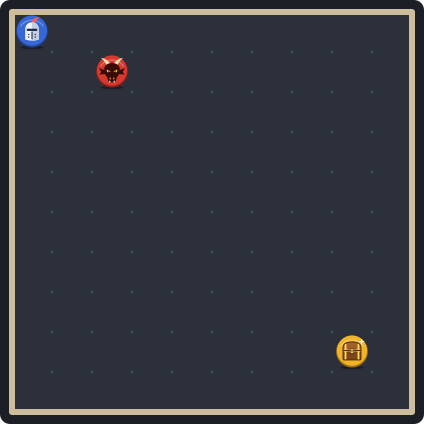

maze as adiacency list:
{(0, 0): [(1, 0), (0, 1)], (0, 1): [(1, 1), (0, 0), (0, 2)], (0, 2): [(1, 2), (0, 1), (0, 3)], (0, 3): [(1, 3), (0, 2), (0, 4)], (0, 4): [(1, 4), (0, 3), (0, 5)], (0, 5): [(1, 5), (0, 4), (0, 6)], (0, 6): [(1, 6), (0, 5), (0, 7)], (0, 7): [(1, 7), (0, 6), (0, 8)], (0, 8): [(1, 8), (0, 7), (0, 9)], (0, 9): [(1, 9), (0, 8)], (1, 0): [(0, 0), (2, 0), (1, 1)], (1, 1): [(0, 1), (2, 1), (1, 0), (1, 2)], (1, 2): [(0, 2), (2, 2), (1, 1), (1, 3)], (1, 3): [(0, 3), (2, 3), (1, 2), (1, 4)], (1, 4): [(0, 4), (2, 4), (1, 3), (1, 5)], (1, 5): [(0, 5), (2, 5), (1, 4), (1, 6)], (1, 6): [(0, 6), (2, 6), (1, 5), (1, 7)], (1, 7): [(0, 7), (2, 7), (1, 6), (1, 8)], (1, 8): [(0, 8), (2, 8), (1, 7), (1, 9)], (1, 9): [(0, 9), (2, 9), (1, 8)], (2, 0): [(1, 0), (3, 0), (2, 1)], (2, 1): [(1, 1), (3, 1), (2, 0), (2, 2)], (2, 2): [(1, 2), (3, 2), (2, 1), (2, 3)], (2, 3): [(1, 3), (3, 3), (2, 2), (2, 4)], (2, 4): [(1, 4), (3, 4), (2, 3), (2, 5)], (2, 5): [(1, 5), (3, 5), (2, 4), (2, 6)], (2,

In [85]:
# The maze from the drawing above: 3 rows, 4 columns, three walls.
## generate a empty maze with default size 10x10
maze = Maze()

## if we want a walled maze, we can use the random_walls() function
## the first argument is the number of the columns,
## density regulates the number of walls: 0 no walls, 1 entirely locked. 

#maze = Maze(10, walls=random_walls(10, density=0.5))


## set up starting positions
knight_position = (0, 0)  
dragon_position = (1, 2)  
goal_position = (8, 8)   

## draw the maze itself, with the knight, dragon, and goal marked.
## print(maze.render(...)) with the same marks draws it as text instead.
display(maze.draw({knight_position: "K", 
                   dragon_position: "D", 
                   goal_position: "G"}))

## now we can also print the entire graph as an adiacency list.
print("maze as adiacency list:")
print(maze.adjacency())

## if we want to access the neighbours of a specific cell, 
## we can use the neighbours() method:
print("neighbours of (0, 0):")
print(maze.neighbours((knight_position)))




# Livello 4,5

UTILIZZO AI: revisione e controllo dell'algoritmo astar. 
COLLABORAZIONE con: Flavia Proia.

Per risolvere questi livelli occorre implementare l'algoritmo astar con oppurtuni accorgimenti e con euristiche diverse a seconda del livello di difficoltà.

L'algoritmo utiliza:
    La funzione di costo step_cost che di default è 1 se non specificata;
    Il dizionario came_from per tenere traccia del predecessore per ricostruire il cammino;
    Il dizionario g_score per tenere traccia del costo reale minimo per raggiungere ogni nodo partendo da start;
    Il set explored per tenere traccia dei nodi già estratti ed espansi;
    Il contatore univoco counter per evitare confronti tra tuple di celle in caso di parità della funzione
    Frontier = [(h(start,goal), counter, start)] per memorizzare le tuple.
    
All'interno del while frontier, prima viene eliminato l'ultimo nodo in frontiera, 
poi se il nodo corrente è il goal, ritorna il cammino dal nodo precedente al goal restituendo path_to(came_from, goal).
Successivamente, esegue il controllo dei vicini nel tentativo di avvicinarsi al goal.
Con il ciclo FOR viene interrogata la stuttura dati del grafo passando current come parametro, verificando se sia già presente o meno in explored per evitare duplicazioni.

Attraverso il ciclo for nb in maze.neighbours(current), per ogni cella possibile, vengono filtrati gli ostacoli e i nodi chiusi.
Se il vicino nb è stato già espanso viene ignorato, se nb == blocked la cella viene scartata per evitare collisioni.
Inoltre viene calcolato il costo reale provvisori (g) con tentative_g = g_score[current] + step_cost(nb)

L'algoritmo controlla se il nuovo percorso verso nb è il migliore rispetto a tutti i precedenti, se è True: 
Viene aggiornato g_score[nb] = tentative_g, viene registrato il predecessore came_from[nb] = current e viene calcolata la stima complessiva.
Incrementa counter e inserisce (f_score, counter, nb) nella coda attraverso heapq.heappush.

Se la frontiera si svuota senza aver mai estratto goal, significa che non esiste alcun percorso tra la partenza e la meta, così l'algoritmo ritorna None.

Livello 4:
Viene utilizzato Astar con euristica manhattan distance.

Livello 5: 
Viene utilizzato Astar con una euristica simile a manhattan distance, calcolando però una minuscola penalità quando il nodo devia dalla retta che collega la partenza all'obiettivo. 




BFS: 16 steps, 95 cells looked at


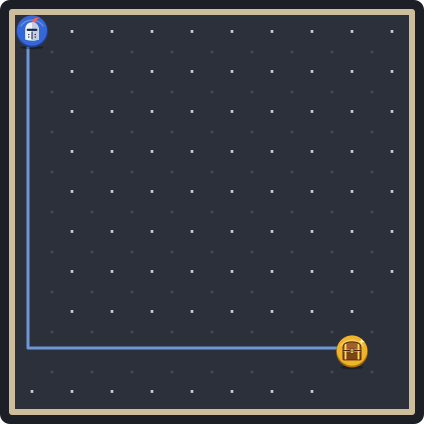

BFS with a budget of 40: looked at 40 cells, the budget is 40; could not look at (4, 4)
BFS                steps: 16   cells looked at: 95
A* with Manhattan  steps: 16   cells looked at: 16


In [86]:
### Search algorithms, and the thinking budget.
#
# The maze counts: inside a `with maze.thinking()` block, every request for
# the neighbours of a cell costs one unit of thinking. Comparing cells,
# manhattan(), your own dicts: free. With a budget, running out raises
# OutOfThought. The dungeon levels charge the knight the same way, once per
# call of reset() and of next_move(), so what you measure here is what the
# knight will pay. Note: maze.adjacency() costs one unit per cell.



from collections import deque
import heapq


def path_to(came_from, goal):
    """The path recorded in came_from, from the start up to goal."""
    path = []
    while goal is not None:
        path.append(goal)
        goal = came_from[goal]
    return path[::-1]


def bfs(maze, start, goal):
    """Shortest path from start to goal as a list of cells, or None.

    Reference implementation. Two habits to keep for A*: the goal is tested
    when a cell is taken out of the frontier, not when it is first seen, and
    came_from doubles as the set of cells already seen."""
    came_from = {start: None}
    frontier = deque([start])
    while frontier:
        cell = frontier.popleft()
        if cell == goal:
            return path_to(came_from, goal)
        for nb in maze.neighbours(cell):          # one unit of thinking
            if nb not in came_from:
                came_from[nb] = cell
                frontier.append(nb)
    return None



with maze.thinking():
    path = bfs(maze, knight_position, goal_position)
print(f"BFS: {len(path) - 1} steps, {maze.expanded} cells looked at")
display(maze.draw({**{cell: "·" for cell in maze.looked if cell not in path},
                   knight_position: "K", goal_position: "G"}, knight_path=path))

try:
    with maze.thinking(budget=40):
        bfs(maze, knight_position, goal_position)
except OutOfThought as e:
    print("BFS with a budget of 40:", e)



def h_zero(cell, goal):
    """No estimate at all: A* becomes uniform-cost search, i.e. Dijkstra."""
    return 0


def h_manhattan(cell, goal):
    """Steps to the goal if there were no walls. Admissible here because every
    step costs at least 1 and changes the Manhattan distance by exactly 1."""
    
    return manhattan(cell,goal)


def h_stronger(cell, goal):
    return manhattan(cell, goal) * 1.001


def astar(maze, start, goal, h=h_stronger, cost=None, blocked=None):
    
    step_cost = cost if cost is not None else (lambda cell: 1)
    came_from = {start: None}
    g_score = {start: 0}
    explored = set()
    counter = 0

    # 3 elementi: (f_score, counter, cell)
    frontier = [(h(start, goal), counter, start)]

    while frontier:
        # Estrai 3 elementi
        f, _, current = heapq.heappop(frontier)

        if current == goal:
            return path_to(came_from, goal)

        if current in explored:
            continue
        explored.add(current)

        for nb in maze.neighbours(current):
            if nb in explored:
                continue
            if blocked is not None and nb == blocked:
                continue

            tentative_g = g_score[current] + step_cost(nb)

            if nb not in g_score or tentative_g < g_score[nb]:
                g_score[nb] = tentative_g
                came_from[nb] = current
                f_score = tentative_g + h(nb, goal)

                counter += 1
                heapq.heappush(frontier, (f_score, counter, nb))

    return None
    

for name, search in [("BFS", bfs),
                     ("A* with Manhattan", astar)]:
    with maze.thinking():
        path = search(maze, knight_position, goal_position)
    steps = len(path) - 1 if path else None
    print(f"{name:18s} steps: {steps}   cells looked at: {maze.expanded}")

In [87]:
"""The knight's strategy. Subclass KnightStrategy to write your own knight.

The knight's maze works similarly to the example maze. 
The information regarding the maze are in the knight's state. 
    
    state.knight, state.dragon, state.goal --> return tuples (row, col), with the positions.    
    state.maze --> is the same maze object as the one above. 
                   you can use the state.maze.neighbours(cell) to get the neighbours of a cell, 
                   state.maze.is_open(a, b) to check if there is a wall between two cells.
                   state.maze.adjacency() gets the adjacency list.
    state.moves_from(cell)        legal moves from a cell (also the cell itself, since the knight can stay put)
    state.dragon_at(k)            where the dragon will be k turns from now, if it can be foreseen
                                  (the PatrolDragon announces its rounds), else None
    state.thinking_budget         in the budgeted levels: how many cells you may look at in one call of
                                  reset() or next_move(). Every state.moves_from(cell), state.maze.neighbours(cell)
                                  or state.maze[cell] costs one; one too many raises OutOfThought and loses
                                  the game, unless you catch it and still return a move (so look up your
                                  legal moves before you start searching).

    those are ignorable:
    state.turn, state.max_turns   turns played so far, and the limit
    state.dragon_acts_on(turn)    whether the dragon moves on a given turn
    state.history   

The knight is himself an agent. 
Of the knight, you have to implement the next_move() method. 
Each turn the game calls next_move(state).
next_move returns a tuple (row, col), corresponding to the cell to move to, which must be one of state.moves_from(state.knight).
each turn the knight state is then updated, with the new positions of the knight and the dragon. 


    class CustomKnight(KnightStrategy):
        def reset(self, state):
            ...  # optional: runs once before each game
                 ## if you put in the knight state the adjacency list, 
                 ## or something else, you can use reset across games to restore the knight. 

        def next_move(self, state)-> tuple(int, int):
            ...  # return the cell to move to

Implement there the strategy to move to the treasure, happy hunting! 


"""
from abc import ABC, abstractmethod


class KnightStrategy(ABC):
    def reset(self, state):
        """Called once before each game with the starting state. Override it
        to precompute things, or to clear anything kept from a previous game."""
    
    @abstractmethod
    def next_move(self, state):
        """Return the cell to move the knight to: one of state.moves_from(state.knight)."""

    def __repr__(self):
        return type(self).__name__


In [88]:
# Here, you can create a custom knight that subclasses KnightStrategy,
# and implements a movement algorithm, able to beat the dragon. 

from collections import deque
import heapq

AI_ASSISTANCE = "none"   # which AI tools you used, and for what

## Try to implement first BFS, then Dijkstra, 
## Then, if you have time, try to beat the harder dragons,
## With new intuitions. 

class CustomKnight(KnightStrategy):

    def reset(self,state):
       
        full_path = astar(state.maze, state.knight, state.goal, blocked=state.dragon) 

        if full_path and len(full_path) > 1:
            self.plan = deque(full_path[1:])
        else:
            self.plan = deque()


    def next_move(self, state):

        if self.plan:
            return self.plan.popleft()

        return state.knight

In [89]:
from dataclasses import dataclass
from typing import Literal


@dataclass
class MazeDisplay:
    """Class for configuring the display of a maze level."""
    DELAY: float = 0.2            # seconds between turns when watching a game
    STYLE: Literal["token", "pixel", "line"] = "token"   # how the game is drawn: "token", "pixel" or "line"

@dataclass
class MazeLevel:
    """Class for configuring the setting of a maze level."""
    size: int | tuple[int, int] = 10            # side of a square maze, or (rows, cols), e.g. (8, 12)
    walls: None | Literal['random'] | list[tuple[tuple[int, int], tuple[int, int]]] = None  # None (no walls), "random", or a list of ((r, c), (r, c)) pairs
    density: float = 0.8        # for walls="random": share of walls kept (1 = no loops at all)
    seed: int | None = None          # random seed for walls="random"
    knight_start: tuple[int, int] = None  # (row, col); None: the top-left corner
    dragon_start: tuple[int, int] = None  # (row, col); None: the centre
    goal: tuple[int, int] = None          # (row, col); None: the bottom-right corner
    max_turns: int = 200
    dragon_every: int = 1       # the dragon moves once every this many turns (2 = half speed)
    allow_stay: bool = True     # whether standing still counts as a move
    level_number: int = 0        # the level number
    pass_rate: float = 0.8
    thinking_budget: int | None = None   # lookups the knight may make per reset() and per next_move(); None: unlimited


    """Class for congiguring the runner of a maze level. """
    dragon: type[DragonStrategy] = StaticDragon  # StaticDragon, GuardDragon, PatrolDragon, GreedyDragon or ChaserDragon

    def settings(self):
        """The game settings, ready for play() and evaluate()."""
        return {key: getattr(self, key) for key in CONFIG}
    




In [90]:
from typing import List
from dataclasses import dataclass, field

LEVELS: dict[str, type[MazeLevel]] = {
    "0": MazeLevel(),
    "1": MazeLevel(walls='random'),
    "2": MazeLevel(walls='random', dragon=GuardDragon),
    "2.5": MazeLevel(walls='random', dragon=GreedyDragon),
    "3": MazeLevel(walls='random', dragon=ChaserDragon, density=0.5, dragon_every=2),
    # Levels with a thinking budget: bigger dungeons, the treasure on the right edge.
    "4": MazeLevel(size=20, walls='random', density=0.5, goal=(10, 19), dragon=StaticDragon, thinking_budget=280, pass_rate=0.95),
    "5": MazeLevel(size=20, walls='random', density=0.3, dragon=StaticDragon, thinking_budget=120, pass_rate=0.95),
    "6": MazeLevel(size=20, walls='random', density=0.5, goal=(10, 19), dragon=PatrolDragon, thinking_budget=280, pass_rate=0.9),
}


In [91]:
@dataclass
class RunnerConfiguration: 
    knight: type[KnightStrategy]      # your knight from the cell above, or GreedyKnight for the baseline
    level_list: List[str] = field(default_factory=lambda: list(LEVELS))
    games: None | int = None  # None: watch one game; a number: play that many games silently and summarise
    delay: float = 0.2            # seconds between turns when watching a game
    style: Literal["token", "pixel", "line"] = "token"   # how the game is drawn: "token", "pixel" or "line"
    show: Literal["lost", "first"] | None = "lost"

    def run(self):

        ## Style is a global variable, so we need to change it outside the cell. 
        ## It could be done better. 
        global STYLE
        STYLE = self.style

        if self.games:
            for name in self.level_list:
                print(f"\n=== Level {name} ===")
                level = LEVELS[name]
                evaluate(self.knight, level.dragon, self.games, **level.settings())
        level = LEVELS[self.level_list[-1]]
        play(self.knight, level.dragon, delay=self.delay, **level.settings())


=== Level 6 ===
CustomKnight vs PatrolDragon: won 35 of 50 (70%)
    35  the knight reached the goal
    15  the dragon caught the knight
  average turns in a win: 29.4
  cells looked at per search: 3 on average, 221 at most, budget 280


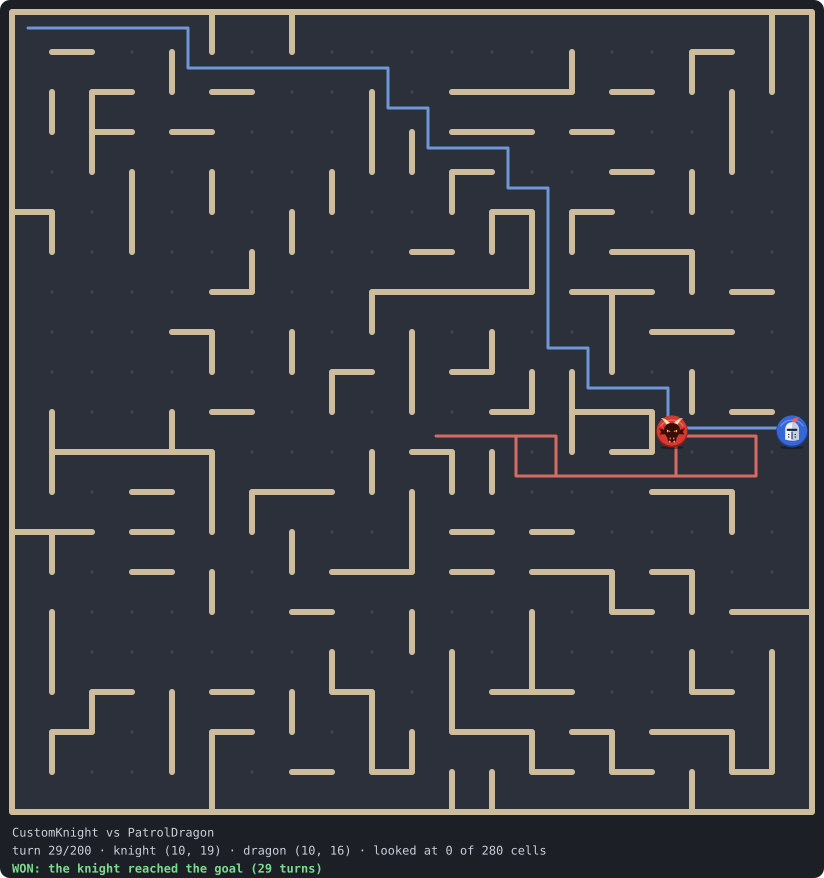

In [92]:
level_results = RunnerConfiguration(
    knight= CustomKnight, 
    games = 50,
    level_list=["6"]
    ).run()
